In [1]:
%pip install qiskit qiskit-aer scipy networkx matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.0 MB/s eta 0:00:00


In [2]:
import qiskit
import scipy
import networkx as nx
import matplotlib.pyplot as plt

print("Qiskit version:", qiskit.__version__)
print("SciPy version:", scipy.__version__)
print("NetworkX version:", nx.__version__)
print("Environment check completed!")


Qiskit version: 2.5.2
SciPy version: 1.16.3
NetworkX version: 3.7
Environment check completed!


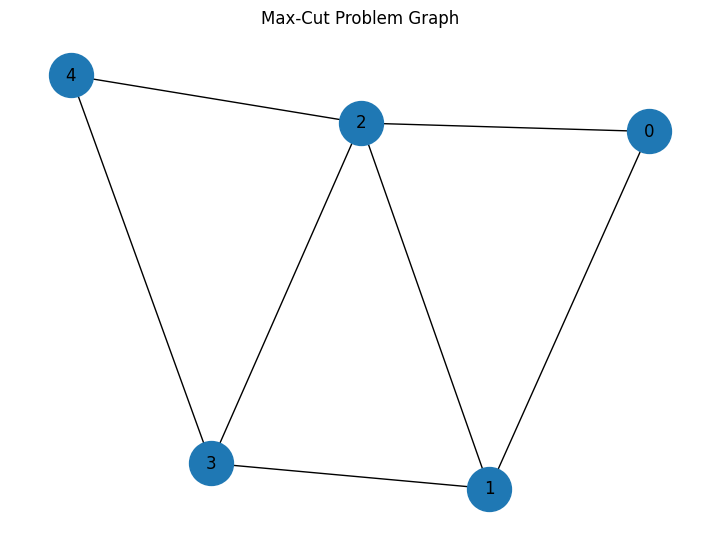

Number of vertices: 5
Number of edges: 7


In [3]:
import networkx as nx
import matplotlib.pyplot as plt

# Small example graph for the Max-Cut problem
G = nx.Graph()
G.add_weighted_edges_from([
    (0, 1, 1),
    (0, 2, 1),
    (1, 2, 1),
    (1, 3, 1),
    (2, 3, 1),
    (2, 4, 1),
    (3, 4, 1)
])

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(7, 5))
nx.draw(
    G, pos,
    with_labels=True,
    node_size=1000,
    font_size=12
)
plt.title("Max-Cut Problem Graph")
plt.show()

print("Number of vertices:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

In [4]:
from itertools import product

def cut_value(graph, partition):
    total = 0

    for u, v, data in graph.edges(data=True):
        if partition[u] != partition[v]:
            total += data.get("weight", 1)

    return total

best_value = -1
best_partition = None

vertices = list(G.nodes())

# Fix the first vertex in group 0 to avoid checking
# both a partition and its equivalent swapped partition.
for remaining in product([0, 1], repeat=len(vertices) - 1):
    partition = (0,) + remaining
    value = cut_value(G, dict(zip(vertices, partition)))

    if value > best_value:
        best_value = value
        best_partition = partition

print("Classical best cut value:", best_value)
print("Partition:", best_partition)

Classical best cut value: 5
Partition: (0, 0, 1, 1, 0)


In [5]:
print("PROJECT: Quantum Max-Cut")
print("CLASSICAL BASELINE")
print("------------------")
print("Vertices:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Best cut value:", best_value)
print("Best partition:", best_partition)
print("Status: Classical baseline completed")

PROJECT: Quantum Max-Cut
CLASSICAL BASELINE
------------------
Vertices: 5
Edges: 7
Best cut value: 5
Best partition: (0, 0, 1, 1, 0)
Status: Classical baseline completed
